In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy import units as u
from astropy.coordinates import SkyCoord
import os
from scipy import stats

### Stellar properities table

In [28]:
data_p113 = pd.read_csv('/data/misfit/benlowe/xshooter/p113/stellar_params/emp_params_FINAL.csv')
data_p113['P#'] = 'P113'
data_p115 = pd.read_csv('/data/misfit/benlowe/xshooter/p115/stellar_params/emp_params_FINAL.csv')
data_p115['P#'] = 'P115'

table_data_p113 = data_p113[['star_id', 'gaia_id', 'ra', 'dec', 'l', 'b', 'parallax', 'parallax_error', 'gmag', 'ebv_corr', 'orbit', 'P#']]
table_data_p115 = data_p115[['star_id', 'gaia_id', 'ra', 'dec', 'l', 'b', 'parallax', 'parallax_error', 'gmag', 'ebv_corr', 'orbit', 'P#']]
comb_table_data = pd.concat([table_data_p113, table_data_p115], ignore_index=True)

# Convert RA and DEC to hh:mm:ss and dd:mm:ss formats
star_coords = SkyCoord(ra=comb_table_data['ra'].to_numpy()*u.degree, dec=comb_table_data['dec'].to_numpy()*u.degree, frame='icrs')
comb_table_data['ra'] = star_coords.ra.to_string(unit=u.hour, sep=':', precision=2)
comb_table_data['dec'] = star_coords.dec.to_string(unit=u.degree, sep=':', precision=2)

comb_table_data = comb_table_data.sort_values(by='star_id')

display(comb_table_data)
print(comb_table_data.to_latex(index=False,
                  float_format="{:.2f}".format))

,star_id,gaia_id,ra,dec,l,b,parallax,parallax_error,gmag,ebv_corr,orbit,P#
0,ra_0103-7050_s163,4689369645972422784,0:53:36.23,-71:04:47.35,302.678953,-46.047367,0.736594,0.025971,15.560211,0.039814,pro_disk,P113
16,ra_0103-7050_s236,4691686763639138688,1:03:18.24,-70:07:30.65,301.454513,-46.969017,0.040552,0.038782,16.437828,0.023469,halo,P115
17,ra_0752-5047_s47,5513982132481251456,7:58:33.25,-50:44:34.27,264.822773,-10.981546,0.108568,0.035912,16.381270,0.296453,halo,P115
1,ra_0834-5220_s316,5321186578181666176,8:36:16.70,-52:56:35.63,269.903058,-7.297586,0.646204,0.045634,16.789020,0.507827,pro_disk,P113
2,ra_1604-2712_s24,6043161513972081024,16:01:40.83,-26:40:51.20,347.281224,19.382796,-0.016893,0.047017,15.533642,0.103916,halo,P113
3,ra_1604-2712_s292,6042817710432143104,16:02:07.43,-27:42:03.79,346.606149,18.580956,0.186226,0.063081,16.774326,0.123317,halo,P113
4,ra_1624-2150_s278,6052240868671385472,16:24:12.43,-21:19:27.92,355.150931,19.323151,0.291232,0.084932,17.255495,0.428400,halo,P113
5,ra_1633-2814_s130,6044035900595959424,16:34:49.20,-28:28:09.76,351.181408,12.819284,0.196550,0.084237,16.882343,0.502348,gse,P113
6,ra_1633-2814_s284,6044482989511923584,16:33:14.64,-28:03:05.13,351.271192,13.355463,0.248548,0.101894,17.126230,0.404852,gse,P113
18,ra_1639-2632_s419,6046167303889429888,16:40:04.95,-26:37:01.99,353.404700,13.131058,0.358469,0.098309,17.178907,0.450000,pro_disk,P115


\begin{tabular}{lrllrrrrrrll}
\toprule
star_id & gaia_id & ra & dec & l & b & parallax & parallax_error & gmag & ebv_corr & orbit & P# \\
\midrule
ra_0103-7050_s163 & 4689369645972422784 & 0:53:36.23 & -71:04:47.35 & 302.68 & -46.05 & 0.74 & 0.03 & 15.56 & 0.04 & pro_disk & P113 \\
ra_0103-7050_s236 & 4691686763639138688 & 1:03:18.24 & -70:07:30.65 & 301.45 & -46.97 & 0.04 & 0.04 & 16.44 & 0.02 & halo & P115 \\
ra_0752-5047_s47 & 5513982132481251456 & 7:58:33.25 & -50:44:34.27 & 264.82 & -10.98 & 0.11 & 0.04 & 16.38 & 0.30 & halo & P115 \\
ra_0834-5220_s316 & 5321186578181666176 & 8:36:16.70 & -52:56:35.63 & 269.90 & -7.30 & 0.65 & 0.05 & 16.79 & 0.51 & pro_disk & P113 \\
ra_1604-2712_s24 & 6043161513972081024 & 16:01:40.83 & -26:40:51.20 & 347.28 & 19.38 & -0.02 & 0.05 & 15.53 & 0.10 & halo & P113 \\
ra_1604-2712_s292 & 6042817710432143104 & 16:02:07.43 & -27:42:03.79 & 346.61 & 18.58 & 0.19 & 0.06 & 16.77 & 0.12 & halo & P113 \\
ra_1624-2150_s278 & 6052240868671385472 & 16:24:12.43 &

### Star exposures table

In [2]:
# Loading the data with exposure times, number of OBs and dates of observations
exposures_df = pd.read_csv('/data/misfit/benlowe/xshooter/p113/stellar_params/emp_obs_dates.csv')
# exposures_df = pd.read_csv('/data/misfit/benlowe/xshooter/p115/stellar_params/emp_obs_dates.csv')


# Loading in the SNR and RVs data
snr_rv_df = pd.read_csv('/data/misfit/benlowe/xshooter/p113/reduced_data/comb_spec_3/star_info.csv')
# snr_rv_df = pd.read_csv('/data/misfit/benlowe/xshooter/p115/reduced_data/comb_spec/star_info.csv')
print(snr_rv_df.columns)

# Merging dataframes together, then applying the heliocentric correction to the RVs
table_data = pd.merge(exposures_df, snr_rv_df[['star_id', 'snr_uvb', 'snr_vis', 'rv_avg', 'rv_avg_err', 'rv_uvb', 'rv_uvb_err', 'rv_vis', 'rv_vis_err', 'heliocor', 'barycor']], on='star_id', how='left')
table_data['rv_uvb_helio'] = table_data['rv_uvb'] + table_data['heliocor']
table_data['rv_vis_helio'] = table_data['rv_vis'] + table_data['heliocor']
table_data['rv_avg_helio'] = table_data['rv_avg'] + table_data['heliocor']

table_data['rv_uvb_bary'] = table_data['rv_uvb'] + table_data['barycor']
table_data['rv_vis_bary'] = table_data['rv_vis'] + table_data['barycor']
table_data['rv_avg_bary'] = table_data['rv_avg'] + table_data['barycor']
# table_data['rv_uvb_bary']

table_data = table_data[['star_id', 'obs', 'exps', 'snr_uvb', 'snr_vis', 'rv_avg_helio', 'rv_avg_err', 'rv_avg_bary', 'rv_avg_err']]
display(table_data)
print(table_data.to_latex(index=False,
                  float_format="{:.3f}".format))

Index(['star_id', 'snr_uvb', 'snr_vis', 'ra', 'dec', 'barycor', 'heliocor',
       'rv_avg', 'rv_avg_err', 'rv_uvb', 'rv_uvb_err', 'rv_vis', 'rv_vis_err',
       'rv_hdelta', 'rv_hdelta_err', 'rv_hgamma', 'rv_hgamma_err', 'rv_hbeta',
       'rv_hbeta_err', 'rv_halpha', 'rv_halpha_err', 'rv_caii849',
       'rv_caii849_err', 'rv_caii854', 'rv_caii854_err', 'rv_caii866',
       'rv_caii866_err'],
      dtype='object')


,star_id,obs,exps,snr_uvb,snr_vis,rv_avg_helio,rv_avg_err,rv_avg_bary,rv_avg_err
0,ra_0103-7050_s163,1,1800,125.759183,129.589052,-17.655261,0.210276,-17.648825,0.210276
1,ra_0834-5220_s316,2,2760,88.695864,145.256296,136.784105,0.221615,136.779305,0.221615
2,ra_1604-2712_s24,1,2700,152.512449,207.383213,171.465255,0.147964,171.468985,0.147964
3,ra_1604-2712_s292,2,2100,84.429111,95.302581,15.438252,0.308310,15.443579,0.308310
4,ra_1624-2150_s278,3,2520,108.125523,149.699693,223.799610,0.311230,223.803843,0.311230
5,ra_1633-2814_s130,4,3120,114.537858,237.310087,174.506909,0.149548,174.512289,0.149548
6,ra_1633-2814_s284,4,3120,122.487576,209.063615,162.371238,0.199538,162.376651,0.199538
7,ra_1648-0653_s38,3,3120,126.621239,184.752043,-35.967481,0.186835,-35.962705,0.186835
8,ra_1656-1433_s143,2,3120,145.015302,347.470042,-76.891309,0.090079,-76.885627,0.090079
9,ra_1658-2454_s22,1,2820,130.657811,227.897299,39.313396,0.096629,39.319669,0.096629


\begin{tabular}{lrrrrrrrr}
\toprule
star_id & obs & exps & snr_uvb & snr_vis & rv_avg_helio & rv_avg_err & rv_avg_bary & rv_avg_err \\
\midrule
ra_0103-7050_s163 & 1 & 1800 & 125.759 & 129.589 & -17.655 & 0.210 & -17.649 & 0.210 \\
ra_0834-5220_s316 & 2 & 2760 & 88.696 & 145.256 & 136.784 & 0.222 & 136.779 & 0.222 \\
ra_1604-2712_s24 & 1 & 2700 & 152.512 & 207.383 & 171.465 & 0.148 & 171.469 & 0.148 \\
ra_1604-2712_s292 & 2 & 2100 & 84.429 & 95.303 & 15.438 & 0.308 & 15.444 & 0.308 \\
ra_1624-2150_s278 & 3 & 2520 & 108.126 & 149.700 & 223.800 & 0.311 & 223.804 & 0.311 \\
ra_1633-2814_s130 & 4 & 3120 & 114.538 & 237.310 & 174.507 & 0.150 & 174.512 & 0.150 \\
ra_1633-2814_s284 & 4 & 3120 & 122.488 & 209.064 & 162.371 & 0.200 & 162.377 & 0.200 \\
ra_1648-0653_s38 & 3 & 3120 & 126.621 & 184.752 & -35.967 & 0.187 & -35.963 & 0.187 \\
ra_1656-1433_s143 & 2 & 3120 & 145.015 & 347.470 & -76.891 & 0.090 & -76.886 & 0.090 \\
ra_1658-2454_s22 & 1 & 2820 & 130.658 & 227.897 & 39.313 & 0.097 & 39.3

Comparing radial velocities with those from the AAT

2.2405566804987966
12.78845270933555


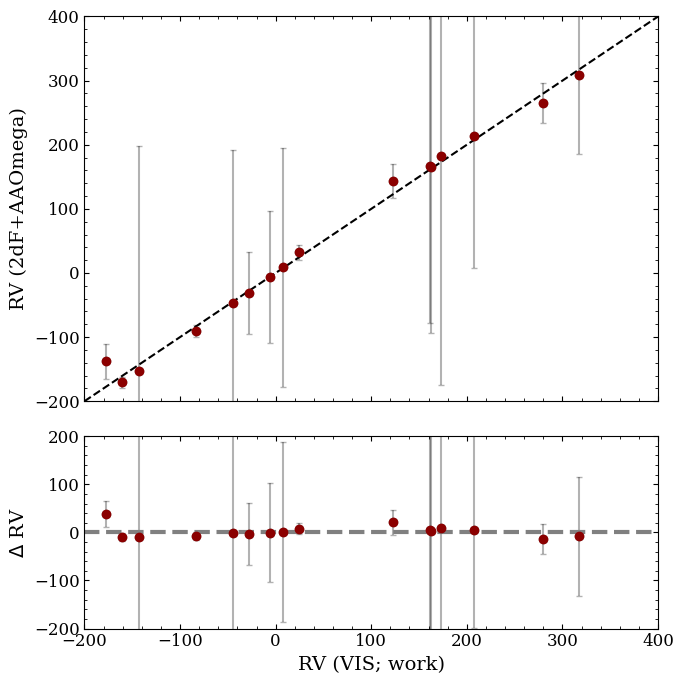

In [ ]:
# Loading in the data
# X-Shooter RV data
xshooter_rv = table_data['rv_uvb_helio'].to_numpy()
xshooter_rv_err = table_data['rv_uvb_err'].to_numpy()

# AAT data
aat_data= pd.read_csv('/data/misfit/benlowe/xshooter/p113/stellar_params/emp_params_FINAL.csv').sort_values(by='star_id')
aat_rv = aat_data['rv'].to_numpy()
aat_rv_err = aat_data['rv_err'].to_numpy()


# Plotting
fig = plt.figure(figsize=[7,7])
gs = fig.add_gridspec(2, 1, wspace=0.1, hspace=0.03, width_ratios=[1], height_ratios=[2, 1])
(ax1), (ax2) = gs.subplots(sharex='col')

# Main plot
ax1.scatter(xshooter_rv, aat_rv, color='darkred', zorder=10)
ax1.errorbar(xshooter_rv, aat_rv, xerr=xshooter_rv_err, yerr=aat_rv_err, fmt='o', color='black', alpha=0.3, zorder=1)
ax1.plot([-200, 400], [-200, 400], color='black', linestyle='--')
ax1.set_xlim(-200, 400)
ax1.set_ylim(-200, 400)
ax1.set_ylabel('RV (2dF+AAOmega)')


# Difference plot
ax2.scatter(xshooter_rv, aat_rv-xshooter_rv, color='darkred', zorder=10)
ax2.errorbar(xshooter_rv, aat_rv-xshooter_rv, yerr=np.sqrt(xshooter_rv_err**2 + aat_rv_err**2), 
             xerr=xshooter_rv_err, fmt='o', color='black', alpha=0.3, zorder=1)


ax2.axhline(0, color='grey', linestyle='--', linewidth=3)
ax2.set_xlabel("RV (VIS; work)")
ax2.set_ylabel("$\Delta$ RV")
ax2.set_xlim(-200, 400)
ax2.set_ylim(bottom=-200, top=200)

gs.tight_layout(fig)

# Calculating the mean difference between the two datasets
print(np.mean(aat_rv-xshooter_rv))
print(np.std(aat_rv-xshooter_rv))

# plt.savefig("/data/misfit/benlowe/xshooter/p113/results/aat_comparision/aat_xshooter_rv.pdf", dpi=300, transparent=False, facecolor="white")
# plt.savefig("/data/misfit/benlowe/xshooter/p113/results/aat_comparision/aat_xshooter_rv.png", dpi=300, transparent=False, facecolor="white")


-5.228341411626068
12.869974867765848


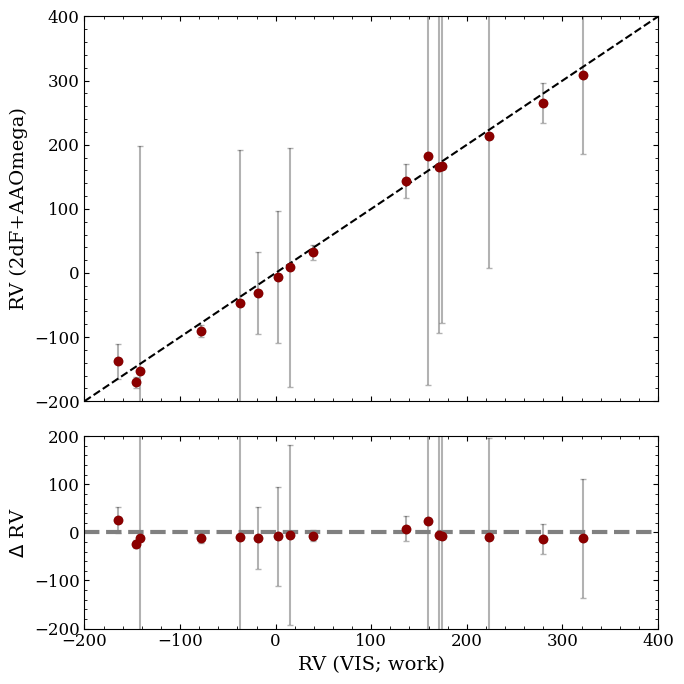

In [ ]:
# Loading in the data
# X-Shooter RV data
xshooter_rv = table_data['rv_vis_helio'].to_numpy()
xshooter_rv_err = table_data['rv_vis_err'].to_numpy()

# AAT data
aat_data= pd.read_csv('/data/misfit/benlowe/xshooter/p113/stellar_params/emp_params_FINAL.csv').sort_values(by='star_id')
aat_rv = aat_data['rv'].to_numpy()
aat_rv_err = aat_data['rv_err'].to_numpy()


# Plotting
fig = plt.figure(figsize=[7,7])
gs = fig.add_gridspec(2, 1, wspace=0.1, hspace=0.03, width_ratios=[1], height_ratios=[2, 1])
(ax1), (ax2) = gs.subplots(sharex='col')

# Main plot
ax1.scatter(xshooter_rv, aat_rv, color='darkred', zorder=10)
ax1.errorbar(xshooter_rv, aat_rv, xerr=xshooter_rv_err, yerr=aat_rv_err, fmt='o', color='black', alpha=0.3, zorder=1)
ax1.plot([-200, 400], [-200, 400], color='black', linestyle='--')
ax1.set_xlim(-200, 400)
ax1.set_ylim(-200, 400)
ax1.set_ylabel('RV (2dF+AAOmega)')


# Difference plot
ax2.scatter(xshooter_rv, aat_rv-xshooter_rv, color='darkred', zorder=10)
ax2.errorbar(xshooter_rv, aat_rv-xshooter_rv, yerr=np.sqrt(xshooter_rv_err**2 + aat_rv_err**2), 
             xerr=xshooter_rv_err, fmt='o', color='black', alpha=0.3, zorder=1)


ax2.axhline(0, color='grey', linestyle='--', linewidth=3)
ax2.set_xlabel("RV (VIS; work)")
ax2.set_ylabel("$\Delta$ RV")
ax2.set_xlim(-200, 400)
ax2.set_ylim(bottom=-200, top=200)

gs.tight_layout(fig)

# Calculating the mean difference between the two datasets
print(np.mean(aat_rv-xshooter_rv))
print(np.std(aat_rv-xshooter_rv))

# plt.savefig("/data/misfit/benlowe/xshooter/p113/results/aat_comparision/aat_xshooter_rv.pdf", dpi=300, transparent=False, facecolor="white")
# plt.savefig("/data/misfit/benlowe/xshooter/p113/results/aat_comparision/aat_xshooter_rv.png", dpi=300, transparent=False, facecolor="white")


-4.943080319229976
12.527388350342715


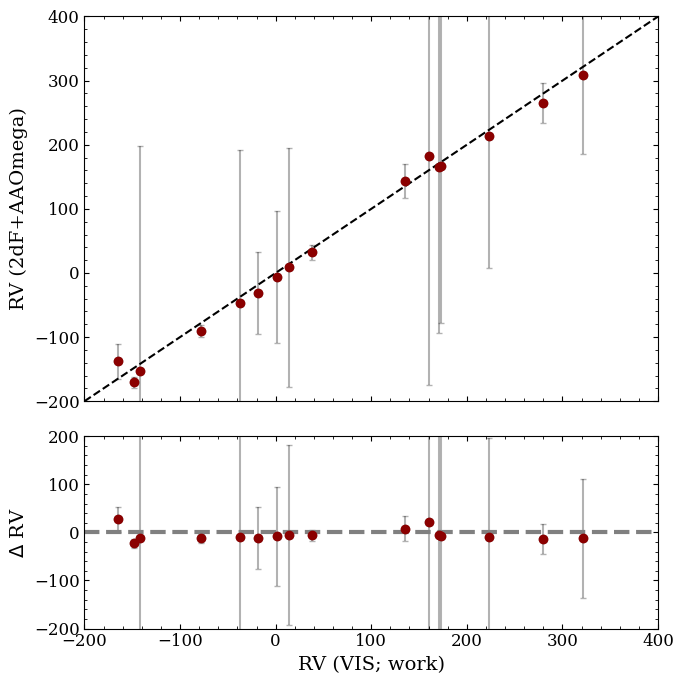

In [ ]:
# Loading in the data
# X-Shooter RV data
xshooter_rv = table_data['rv_avg_helio'].to_numpy()
xshooter_rv_err = table_data['rv_avg_err'].to_numpy()

# AAT data
aat_data= pd.read_csv('/data/misfit/benlowe/xshooter/p113/stellar_params/emp_params_FINAL.csv').sort_values(by='star_id')
aat_rv = aat_data['rv'].to_numpy()
aat_rv_err = aat_data['rv_err'].to_numpy()


# Plotting
fig = plt.figure(figsize=[7,7])
gs = fig.add_gridspec(2, 1, wspace=0.1, hspace=0.03, width_ratios=[1], height_ratios=[2, 1])
(ax1), (ax2) = gs.subplots(sharex='col')

# Main plot
ax1.scatter(xshooter_rv, aat_rv, color='darkred', zorder=10)
ax1.errorbar(xshooter_rv, aat_rv, xerr=xshooter_rv_err, yerr=aat_rv_err, fmt='o', color='black', alpha=0.3, zorder=1)
ax1.plot([-200, 400], [-200, 400], color='black', linestyle='--')
ax1.set_xlim(-200, 400)
ax1.set_ylim(-200, 400)
ax1.set_ylabel('RV (2dF+AAOmega)')


# Difference plot
ax2.scatter(xshooter_rv, aat_rv-xshooter_rv, color='darkred', zorder=10)
ax2.errorbar(xshooter_rv, aat_rv-xshooter_rv, yerr=np.sqrt(xshooter_rv_err**2 + aat_rv_err**2), 
             xerr=xshooter_rv_err, fmt='o', color='black', alpha=0.3, zorder=1)


ax2.axhline(0, color='grey', linestyle='--', linewidth=3)
ax2.set_xlabel("RV (VIS; work)")
ax2.set_ylabel("$\Delta$ RV")
ax2.set_xlim(-200, 400)
ax2.set_ylim(bottom=-200, top=200)

gs.tight_layout(fig)

# Calculating the mean difference between the two datasets
print(np.mean(aat_rv-xshooter_rv))
print(np.std(aat_rv-xshooter_rv))

# plt.savefig("/data/misfit/benlowe/xshooter/p113/results/aat_comparision/aat_xshooter_rv.pdf", dpi=300, transparent=False, facecolor="white")
# plt.savefig("/data/misfit/benlowe/xshooter/p113/results/aat_comparision/aat_xshooter_rv.png", dpi=300, transparent=False, facecolor="white")


### Median uncertainties for all measured elemental abundances

In [8]:
abunds

['/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Al_I_allabunds.csv',
 '/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Ba_II_allabunds.csv',
 '/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/C_I_allabunds.csv',
 '/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Ca_II_allabunds.csv',
 '/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Co_I_allabunds.csv',
 '/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Cr_I_allabunds.csv',
 '/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Eu_II_allabunds.csv',
 '/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Mg_I_allabunds.csv',
 '/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Mn_I_allabunds.csv',
 '/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/N_I_allabunds.csv',
 '/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Na_I_allabunds.csv',
 '/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Ni_I_allabunds.csv',
 '/data/misfit/benlowe/xshooter/p115/korg_data/all_

In [25]:
# Loading in the abundance data
path = '/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/'
abunds = [path + f for f in os.listdir(path) if f.endswith('_allabunds.csv')]
abunds.sort()

# Extracting the median errors for each element
al_I_abunds = pd.read_csv(abunds[0])
al_I_med_tefferr = al_I_abunds['bestfit_abund_tefferr_xfe'].median()
al_I_med_loggerr = al_I_abunds['bestfit_abund_loggerr_xfe'].median()
al_I_med_vmicerr = al_I_abunds['bestfit_abund_vmicerr_xfe'].median()

ba_II_abunds = pd.read_csv(abunds[1])
ba_II_med_tefferr = ba_II_abunds['bestfit_abund_tefferr_xfe'].median()
ba_II_med_loggerr = ba_II_abunds['bestfit_abund_loggerr_xfe'].median()
ba_II_med_vmicerr = ba_II_abunds['bestfit_abund_vmicerr_xfe'].median()

c_I_abunds = pd.read_csv(abunds[2])
c_I_med_tefferr = c_I_abunds['bestfit_abund_tefferr_xfe'].median()
c_I_med_loggerr = c_I_abunds['bestfit_abund_loggerr_xfe'].median()
c_I_med_vmicerr = c_I_abunds['bestfit_abund_vmicerr_xfe'].median()

ca_II_abunds = pd.read_csv(abunds[3])
ca_II_med_tefferr = ca_II_abunds['bestfit_abund_tefferr_xfe'].median()
ca_II_med_loggerr = ca_II_abunds['bestfit_abund_loggerr_xfe'].median()
ca_II_med_vmicerr = ca_II_abunds['bestfit_abund_vmicerr_xfe'].median()

co_I_abunds = pd.read_csv(abunds[4])
co_I_med_tefferr = co_I_abunds['bestfit_abund_tefferr_xfe'].median()
co_I_med_loggerr = co_I_abunds['bestfit_abund_loggerr_xfe'].median() 
co_I_med_vmicerr = co_I_abunds['bestfit_abund_vmicerr_xfe'].median()

cr_I_abunds = pd.read_csv(abunds[5])
cr_I_med_tefferr = cr_I_abunds['bestfit_abund_tefferr_xfe'].median()
cr_I_med_loggerr = cr_I_abunds['bestfit_abund_loggerr_xfe'].median()
cr_I_med_vmicerr = cr_I_abunds['bestfit_abund_vmicerr_xfe'].median()

eu_II_abunds = pd.read_csv(abunds[6])
eu_II_med_tefferr = eu_II_abunds['bestfit_abund_tefferr_xfe'].median()
eu_II_med_loggerr = eu_II_abunds['bestfit_abund_loggerr_xfe'].median()
eu_II_med_vmicerr = eu_II_abunds['bestfit_abund_vmicerr_xfe'].median()

mg_I_abunds = pd.read_csv(abunds[7])
mg_I_med_tefferr = mg_I_abunds['bestfit_abund_tefferr_xfe'].median()
mg_I_med_loggerr = mg_I_abunds['bestfit_abund_loggerr_xfe'].median()
mg_I_med_vmicerr = mg_I_abunds['bestfit_abund_vmicerr_xfe'].median()

mn_I_abunds = pd.read_csv(abunds[8])
mn_I_med_tefferr = mn_I_abunds['bestfit_abund_tefferr_xfe'].median()
mn_I_med_loggerr = mn_I_abunds['bestfit_abund_loggerr_xfe'].median()
mn_I_med_vmicerr = mn_I_abunds['bestfit_abund_vmicerr_xfe'].median()

n_I_abunds = pd.read_csv(abunds[9])
n_I_med_tefferr = n_I_abunds['bestfit_abund_tefferr_xfe'].median()
n_I_med_loggerr = n_I_abunds['bestfit_abund_loggerr_xfe'].median()
n_I_med_vmicerr = n_I_abunds['bestfit_abund_vmicerr_xfe'].median()

na_I_abunds = pd.read_csv(abunds[10])
na_I_med_tefferr = na_I_abunds['bestfit_abund_tefferr_xfe'].median()
na_I_med_loggerr = na_I_abunds['bestfit_abund_loggerr_xfe'].median()
na_I_med_vmicerr = na_I_abunds['bestfit_abund_vmicerr_xfe'].median()

ni_I_abunds = pd.read_csv(abunds[11])
ni_I_med_tefferr = ni_I_abunds['bestfit_abund_tefferr_xfe'].median()
ni_I_med_loggerr = ni_I_abunds['bestfit_abund_loggerr_xfe'].median()
ni_I_med_vmicerr = ni_I_abunds['bestfit_abund_vmicerr_xfe'].median()

sc_II_abunds = pd.read_csv(abunds[12])
sc_II_med_tefferr = sc_II_abunds['bestfit_abund_tefferr_xfe'].median()
sc_II_med_loggerr = sc_II_abunds['bestfit_abund_loggerr_xfe'].median()
sc_II_med_vmicerr = sc_II_abunds['bestfit_abund_vmicerr_xfe'].median()

si_I_abunds = pd.read_csv(abunds[13])
si_I_med_tefferr = si_I_abunds['bestfit_abund_tefferr_xfe'].median()
si_I_med_loggerr = si_I_abunds['bestfit_abund_loggerr_xfe'].median()
si_I_med_vmicerr = si_I_abunds['bestfit_abund_vmicerr_xfe'].median()

sr_II_abunds = pd.read_csv(abunds[14])
sr_II_med_tefferr = sr_II_abunds['bestfit_abund_tefferr_xfe'].median()
sr_II_med_loggerr = sr_II_abunds['bestfit_abund_loggerr_xfe'].median()
sr_II_med_vmicerr = sr_II_abunds['bestfit_abund_vmicerr_xfe'].median()

ti_II_abunds = pd.read_csv(abunds[15])
ti_II_med_tefferr = ti_II_abunds['bestfit_abund_tefferr_xfe'].median()
ti_II_med_loggerr = ti_II_abunds['bestfit_abund_loggerr_xfe'].median()
ti_II_med_vmicerr = ti_II_abunds['bestfit_abund_vmicerr_xfe'].median()

fe_I_abunds = pd.read_csv('/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/stellar_params_combined.csv')
fe_I_med_tefferr = fe_I_abunds['Fe_tefferr'].median()
fe_I_med_loggerr = fe_I_abunds['Fe_loggerr'].median()
fe_I_med_vmicerr = fe_I_abunds['Fe_vmicerr'].median()

# Storing into dataframe
# abund_data = {
#     'Element': ['Al I', 'Ba II', 'C I', 'Ca II', 'Co I', 'Cr I', 'Eu II', 'Mg I', 'Mn I', 'N I', 'Na I', 'Ni I', 'Sc II', 'Si I', 'Sr II', 'Ti II', 'Fe I'],
#     'Median Teff Error': [al_I_med_tefferr, ba_II_med_tefferr, c_I_med_tefferr, ca_II_med_tefferr, co_I_med_tefferr, cr_I_med_tefferr, eu_II_med_tefferr, mg_I_med_tefferr,
#                           mn_I_med_tefferr, n_I_med_tefferr, na_I_med_tefferr, ni_I_med_tefferr, sc_II_med_tefferr, si_I_med_tefferr, sr_II_med_tefferr, ti_II_med_tefferr, fe_I_med_tefferr],
#     'Median Logg Error': [al_I_med_loggerr, ba_II_med_loggerr, c_I_med_loggerr, ca_II_med_loggerr, co_I_med_loggerr, cr_I_med_loggerr,
#                           eu_II_med_loggerr, mg_I_med_loggerr, mn_I_med_loggerr, n_I_med_loggerr, na_I_med_loggerr, ni_I_med_loggerr,
#                           sc_II_med_loggerr, si_I_med_loggerr, sr_II_med_loggerr, ti_II_med_loggerr, fe_I_med_loggerr],
#     'Median Vmic Error': [al_I_med_vmicerr, ba_II_med_vmicerr, c_I_med_vmicerr, ca_II_med_vmicerr, co_I_med_vmicerr, cr_I_med_vmicerr,
#                           eu_II_med_vmicerr, mg_I_med_vmicerr, mn_I_med_vmicerr, n_I_med_vmicerr, na_I_med_vmicerr, ni_I_med_vmicerr,
#                           sc_II_med_vmicerr, si_I_med_vmicerr, sr_II_med_vmicerr, ti_II_med_vmicerr, fe_I_med_vmicerr]
# }

abund_data = {
    'Element': ['C (CH)', 'N (NH)', '\ion{Na}{I}', '\ion{Mg}{I}', '\ion{Al}{I}', '\ion{Si}{I}', '\ion{Ca}{II}', '\ion{Sc}{II}', 
                '\ion{Ti}{II}', '\ion{Cr}{I}', '\ion{Mn}{I}', '\ion{Fe}{I}', '\ion{Co}{I}', '\ion{Ni}{I}', '\ion{Sr}{II}', '\ion{Ba}{II}', '\ion{Eu}{II}'],
    'Median Teff Error': [c_I_med_tefferr, n_I_med_tefferr, na_I_med_tefferr, mg_I_med_tefferr, al_I_med_tefferr, si_I_med_tefferr, ca_II_med_tefferr, sc_II_med_tefferr,
                          ti_II_med_tefferr, cr_I_med_tefferr, mn_I_med_tefferr, fe_I_med_tefferr, co_I_med_tefferr, ni_I_med_tefferr, sr_II_med_tefferr, ba_II_med_tefferr, eu_II_med_tefferr],
    'Median Logg Error': [c_I_med_loggerr, n_I_med_loggerr, na_I_med_loggerr, mg_I_med_loggerr, al_I_med_loggerr, si_I_med_loggerr, ca_II_med_loggerr, sc_II_med_loggerr,
                          ti_II_med_loggerr, cr_I_med_loggerr, mn_I_med_loggerr, fe_I_med_loggerr, co_I_med_loggerr, ni_I_med_loggerr, sr_II_med_loggerr, ba_II_med_loggerr, eu_II_med_loggerr],
    'Median Vmic Error': [c_I_med_vmicerr, n_I_med_vmicerr, na_I_med_vmicerr, mg_I_med_vmicerr, al_I_med_vmicerr, si_I_med_vmicerr, ca_II_med_vmicerr, sc_II_med_vmicerr,
                          ti_II_med_vmicerr, cr_I_med_vmicerr, mn_I_med_vmicerr, fe_I_med_vmicerr, co_I_med_vmicerr, ni_I_med_vmicerr, sr_II_med_vmicerr, ba_II_med_vmicerr, eu_II_med_vmicerr]
}
abund_data
abunds_df = pd.DataFrame(abund_data)
# abunds_df = abunds_df.sort_values(by='Element').reset_index(drop=True)
print(abunds_df.to_latex(index=False,
                  float_format="{:.2f}".format))

\begin{tabular}{lrrr}
\toprule
Element & Median Teff Error & Median Logg Error & Median Vmic Error \\
\midrule
C (CH) & 0.22 & 0.11 & 0.00 \\
N (NH) & 0.24 & 0.13 & 0.04 \\
\ion{Na}{I} & 0.12 & 0.06 & 0.11 \\
\ion{Mg}{I} & 0.11 & 0.09 & 0.08 \\
\ion{Al}{I} & 0.05 & 0.02 & 0.11 \\
\ion{Si}{I} & 0.16 & 0.12 & 0.09 \\
\ion{Ca}{II} & 0.06 & 0.02 & 0.02 \\
\ion{Sc}{II} & 0.04 & 0.13 & 0.12 \\
\ion{Ti}{II} & 0.04 & 0.09 & 0.08 \\
\ion{Cr}{I} & 0.13 & 0.01 & 0.05 \\
\ion{Mn}{I} & 0.18 & 0.05 & 0.06 \\
\ion{Fe}{I} & 0.11 & 0.08 & 0.13 \\
\ion{Co}{I} & 0.13 & 0.02 & 0.04 \\
\ion{Ni}{I} & 0.09 & 0.01 & 0.04 \\
\ion{Sr}{II} & 0.07 & 0.07 & 0.20 \\
\ion{Ba}{II} & 0.07 & 0.09 & 0.03 \\
\ion{Eu}{II} & 0.12 & 0.12 & 0.05 \\
\bottomrule
\end{tabular}



### Stellar parameters table

In [7]:
# Loading in the P113 data
korg_params_p113_df = pd.read_csv('/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter9/stellar_params.csv')
star_params_p113_df = pd.read_csv('/data/misfit/benlowe/xshooter/p113/stellar_params/emp_params_FINAL.csv')
korg_params_p113_df.keys()

table_data_p113 = pd.merge(star_params_p113_df[['star_id', 'teff', 'randteff_std', 'logg', 'randlogg_std']], korg_params_p113_df[['star_id', 'Fe_it1', 'Fe_comberr', 'vmic']], on='star_id', how='left')
table_data_p113 = table_data_p113.sort_values(by='star_id').reset_index(drop=True) 
table_data_p113 = table_data_p113[['star_id', 'teff', 'randteff_std', 'logg', 'randlogg_std', 'Fe_it1', 'Fe_comberr', 'vmic']]
table_data_p113['P#'] = 'P113'

# Loading in the P115 data
korg_params_p115_df = pd.read_csv('/data/misfit/benlowe/xshooter/p115/korg_data/abunds_v2/final_iter9/stellar_params.csv')
star_params_p115_df = pd.read_csv('/data/misfit/benlowe/xshooter/p115/stellar_params/emp_params_FINAL.csv')
table_data_p115 = pd.merge(star_params_p115_df[['star_id', 'teff', 'randteff_std', 'logg', 'randlogg_std']], korg_params_p115_df[['star_id', 'Fe_it1', 'Fe_comberr', 'vmic']], on='star_id', how='left')
table_data_p115 = table_data_p115.sort_values(by='star_id').reset_index(drop=True) 
table_data_p115 = table_data_p115[['star_id', 'teff', 'randteff_std', 'logg', 'randlogg_std', 'Fe_it1', 'Fe_comberr', 'vmic']]
table_data_p115['P#'] = 'P115'

# Combining the two tables
table_data = pd.concat([table_data_p113, table_data_p115], ignore_index=True)
table_data = table_data.sort_values(by='star_id').reset_index(drop=True)

# Calculating the error in vmic (because I didn't do that oops)
def calc_vmic_error(teff, teff_err, logg, logg_err):
    logg_ = logg - 4.0
    teff_ = teff - 5500
    vmic_err = np.sqrt((3.16E-4 - 2.86E-4 * logg_)**2 * teff_err**2 + (-0.253 - 2.86E-4 * teff_ + 0.330 * logg_)**2 * logg_err**2)
    return vmic_err

table_data['vmic_err'] = calc_vmic_error(table_data['teff'], table_data['randteff_std'], table_data['logg'], table_data['randlogg_std'])

print(table_data[['star_id', 'P#', 'teff', 'randteff_std', 'logg', 'randlogg_std', 'Fe_it1', 'Fe_comberr', 'vmic', 'vmic_err']].to_latex(index=False,
                  float_format="{:.3f}".format))

\begin{tabular}{llrrrrrrrr}
\toprule
star_id & P# & teff & randteff_std & logg & randlogg_std & Fe_it1 & Fe_comberr & vmic & vmic_err \\
\midrule
ra_0103-7050_s163 & P113 & 6298.807 & 32.299 & 4.492 & 0.030 & -2.358 & 0.061 & 1.253 & 0.011 \\
ra_0103-7050_s236 & P115 & 4622.578 & 13.812 & 0.995 & 0.302 & -2.884 & 0.067 & 2.417 & 0.301 \\
ra_0752-5047_s47 & P115 & 4782.205 & 88.672 & 2.392 & 0.619 & -3.052 & 0.077 & 1.475 & 0.365 \\
ra_0834-5220_s316 & P113 & 5959.305 & 256.779 & 4.286 & 0.066 & -2.615 & 0.137 & 1.247 & 0.063 \\
ra_1604-2712_s24 & P113 & 5002.685 & 35.337 & 1.892 & 0.089 & -2.526 & 0.060 & 2.008 & 0.079 \\
ra_1604-2712_s292 & P113 & 5783.249 & 58.412 & 3.405 & 0.205 & -3.096 & 0.066 & 1.545 & 0.112 \\
ra_1624-2150_s278 & P113 & 6381.865 & 243.735 & 3.974 & 0.196 & -2.667 & 0.058 & 1.490 & 0.128 \\
ra_1633-2814_s130 & P113 & 4997.869 & 161.388 & 1.850 & 0.775 & -3.350 & 0.069 & 2.037 & 0.652 \\
ra_1633-2814_s284 & P113 & 5261.142 & 147.691 & 2.448 & 0.671 & -3.893 & 0.06

In [6]:
table_data_p115

,star_id,teff,randteff_std,logg,randlogg_std,Fe_it1,Fe_comberr,vmic,P#
0,ra_0103-7050_s236,4622.578329,13.811537,0.994550,0.302448,-2.883631,0.067304,2.417319,P115
1,ra_0752-5047_s47,4782.205419,88.671622,2.391622,0.619000,-3.051738,0.077258,1.474749,P115
2,ra_1639-2632_s419,5356.455582,133.851422,2.873584,0.499023,-2.034058,0.063943,1.600734,P115
3,ra_1648-2642_s91,5056.051117,71.092761,2.018700,0.322760,-2.808558,0.069077,1.955132,P115
4,ra_1659-2154_s261,5370.037228,145.715926,2.921514,0.459300,-2.194068,0.064467,1.581619,P115
5,ra_1659-2154_s347,5476.914866,105.334284,3.079300,0.360303,-2.829687,0.065224,1.557432,P115
6,ra_1752-4300_s155,4797.406576,49.908187,1.413650,0.209130,-2.907340,0.067832,2.214340,P115


### Mean and standard deviation of elements across the kinematic groups table

In [ ]:
# Loading in the chemical abundances
abunds_path = '/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final/'
abunds_dirs = [abunds_path + f for f in os.listdir(abunds_path) if f.endswith('I_abunds.csv')]

# Opening the files and extracting the mean and standard deviation of elements across the kinematic groups
orb_data = []

for abunds_file in abunds_dirs:
    abunds_df = pd.read_csv(abunds_file)
    
    # Making sure we only take detections
    abunds_df = abunds_df[abunds_df['detection'] == 'Y']
    
    el = abunds_df['el'].iloc[0]
    
    if el == 'C_I':
        abunds_df.loc[abunds_df['star_id'] == 'ra_1656-1433_s143', 'bestfit_abund_xfe'] = 0.358195

    display(abunds_df[['star_id', 'el', 'orbit', 'bestfit_abund_xfe']])
    
    prodisk_mean = abunds_df[abunds_df['orbit'] == 'pro_disk']['bestfit_abund_xfe'].mean()
    prodisk_std = abunds_df[abunds_df['orbit'] == 'pro_disk']['bestfit_abund_xfe'].std()
    halo_mean = abunds_df[abunds_df['orbit'] == 'halo']['bestfit_abund_xfe'].mean()
    halo_std = abunds_df[abunds_df['orbit'] == 'halo']['bestfit_abund_xfe'].std()
    gse_mean = abunds_df[abunds_df['orbit'] == 'gse']['bestfit_abund_xfe'].mean()
    gse_std = abunds_df[abunds_df['orbit'] == 'gse']['bestfit_abund_xfe'].std()
    
    prodisk_nstars = len(abunds_df[abunds_df['orbit'] == 'pro_disk'])
    halo_nstars = len(abunds_df[abunds_df['orbit'] == 'halo'])
    gse_nstars = len(abunds_df[abunds_df['orbit'] == 'gse'])
    
    orb_abunds = {
        'el': el,
        'pro_disk_mean': prodisk_mean,
        'pro_disk_std': prodisk_std,
        'pro_disk_nstars': prodisk_nstars,
        'halo_mean': halo_mean,
        'halo_std': halo_std,
        'halo_nstars': halo_nstars,
        'gse_mean': gse_mean,
        'gse_std': gse_std,
        'gse_nstars': gse_nstars
    }
    orb_data.append(orb_abunds)
    
orb_df = pd.DataFrame(orb_data)

# # Sorting dataframe by atomic number
# els_order = ['C_I', 'N_I', 'Na_I', 'Mg_I', 'Al_I', 'Si_I', 'Ca_II', 'Sc_II', 'Ti_II', 'Cr_I', 'Mn_I', 'Fe_I', 'Co_I', 'Ni_I', 'Sr_II', 'Ba_II', 'Eu_II']

# # Set 'el' as a categorical column with your specified order
# cat_type = pd.CategoricalDtype(categories=els_order, ordered=True)
# orb_df['el'] = orb_df['el'].astype(cat_type)

# # Sort by 'el'
# orb_df = orb_df.sort_values('el').reset_index(drop=True)


# print(orb_df.to_latex(index=False,
#                   float_format="{:.2f}".format))

,star_id,el,orbit,bestfit_abund_xfe
0,ra_0103-7050_s163,Al_I,pro_disk,-0.911585
1,ra_0834-5220_s316,Al_I,pro_disk,-1.088198
2,ra_1604-2712_s24,Al_I,halo,-0.238237
3,ra_1604-2712_s292,Al_I,halo,-0.998076
4,ra_1624-2150_s278,Al_I,halo,-1.035326
5,ra_1633-2814_s130,Al_I,gse,-0.721554
6,ra_1633-2814_s284,Al_I,gse,-0.804129
7,ra_1648-0653_s38,Al_I,pro_disk,-1.224484
8,ra_1656-1433_s143,Al_I,halo,-0.529801
9,ra_1658-2454_s22,Al_I,halo,-0.671310


,star_id,el,orbit,bestfit_abund_xfe
0,ra_0103-7050_s163,Ba_II,pro_disk,-0.505398
1,ra_0834-5220_s316,Ba_II,pro_disk,-0.384667
2,ra_1604-2712_s24,Ba_II,halo,-0.886251
7,ra_1648-0653_s38,Ba_II,pro_disk,-0.871406
8,ra_1656-1433_s143,Ba_II,halo,0.787183
9,ra_1658-2454_s22,Ba_II,halo,-1.442353
10,ra_1659-2154_s114,Ba_II,halo,-1.007313
11,ra_1709-2130_s102,Ba_II,halo,-1.513305
12,ra_1752-4300_s214,Ba_II,halo,-0.793301
13,ra_1752-4300_s269,Ba_II,halo,-1.663041


,star_id,el,orbit,bestfit_abund_xfe
1,ra_0834-5220_s316,C_I,pro_disk,-0.070000
2,ra_1604-2712_s24,C_I,halo,0.070000
5,ra_1633-2814_s130,C_I,gse,0.340000
6,ra_1633-2814_s284,C_I,gse,0.440000
7,ra_1648-0653_s38,C_I,pro_disk,-0.250000
8,ra_1656-1433_s143,C_I,halo,0.358195
9,ra_1658-2454_s22,C_I,halo,-0.460000
10,ra_1659-2154_s114,C_I,halo,-0.030000
11,ra_1709-2130_s102,C_I,halo,-0.070000
12,ra_1752-4300_s214,C_I,halo,0.800000


,star_id,el,orbit,bestfit_abund_xfe
0,ra_0103-7050_s163,Ca_II,pro_disk,0.144885
1,ra_0834-5220_s316,Ca_II,pro_disk,0.335718
2,ra_1604-2712_s24,Ca_II,halo,0.218059
3,ra_1604-2712_s292,Ca_II,halo,0.327977
4,ra_1624-2150_s278,Ca_II,halo,0.127461
5,ra_1633-2814_s130,Ca_II,gse,0.295623
6,ra_1633-2814_s284,Ca_II,gse,0.516842
7,ra_1648-0653_s38,Ca_II,pro_disk,0.238750
8,ra_1656-1433_s143,Ca_II,halo,0.350262
9,ra_1658-2454_s22,Ca_II,halo,0.300496


,star_id,el,orbit,bestfit_abund_xfe
2,ra_1604-2712_s24,Co_I,halo,0.136186
5,ra_1633-2814_s130,Co_I,gse,0.103164
6,ra_1633-2814_s284,Co_I,gse,0.848948
8,ra_1656-1433_s143,Co_I,halo,-0.114930
9,ra_1658-2454_s22,Co_I,halo,0.218828
10,ra_1659-2154_s114,Co_I,halo,0.340431
11,ra_1709-2130_s102,Co_I,halo,0.245880
12,ra_1752-4300_s214,Co_I,halo,-0.090465
13,ra_1752-4300_s269,Co_I,halo,0.191774
14,ra_1752-4300_s6,Co_I,halo,0.187436


...

,star_id,el,orbit,bestfit_abund_xfe
2,ra_1604-2712_s24,Ni_I,halo,-0.177736
5,ra_1633-2814_s130,Ni_I,gse,-0.200960
7,ra_1648-0653_s38,Ni_I,pro_disk,0.172529
8,ra_1656-1433_s143,Ni_I,halo,-0.080630
9,ra_1658-2454_s22,Ni_I,halo,0.321062
10,ra_1659-2154_s114,Ni_I,halo,0.026995
11,ra_1709-2130_s102,Ni_I,halo,-0.045499
12,ra_1752-4300_s214,Ni_I,halo,-0.012031
13,ra_1752-4300_s269,Ni_I,halo,0.163022
14,ra_1752-4300_s6,Ni_I,halo,-0.163068


,star_id,el,orbit,bestfit_abund_xfe
0,ra_0103-7050_s163,Sc_II,pro_disk,-0.275096
1,ra_0834-5220_s316,Sc_II,pro_disk,-0.457788
2,ra_1604-2712_s24,Sc_II,halo,-0.065942
4,ra_1624-2150_s278,Sc_II,halo,0.110490
5,ra_1633-2814_s130,Sc_II,gse,-0.330984
6,ra_1633-2814_s284,Sc_II,gse,0.059387
7,ra_1648-0653_s38,Sc_II,pro_disk,-0.514705
8,ra_1656-1433_s143,Sc_II,halo,0.199107
9,ra_1658-2454_s22,Sc_II,halo,0.037372
10,ra_1659-2154_s114,Sc_II,halo,0.072260


,star_id,el,orbit,bestfit_abund_xfe
0,ra_0103-7050_s163,Si_I,pro_disk,0.326460
1,ra_0834-5220_s316,Si_I,pro_disk,0.379945
2,ra_1604-2712_s24,Si_I,halo,0.534248
3,ra_1604-2712_s292,Si_I,halo,0.076036
4,ra_1624-2150_s278,Si_I,halo,-0.039786
5,ra_1633-2814_s130,Si_I,gse,0.450591
6,ra_1633-2814_s284,Si_I,gse,0.527876
7,ra_1648-0653_s38,Si_I,pro_disk,0.210254
8,ra_1656-1433_s143,Si_I,halo,0.457298
9,ra_1658-2454_s22,Si_I,halo,0.069303


,star_id,el,orbit,bestfit_abund_xfe
0,ra_0103-7050_s163,Sr_II,pro_disk,0.019595
1,ra_0834-5220_s316,Sr_II,pro_disk,0.201461
2,ra_1604-2712_s24,Sr_II,halo,-0.244649
3,ra_1604-2712_s292,Sr_II,halo,-1.213389
4,ra_1624-2150_s278,Sr_II,halo,-0.299866
5,ra_1633-2814_s130,Sr_II,gse,-1.272750
6,ra_1633-2814_s284,Sr_II,gse,0.454392
7,ra_1648-0653_s38,Sr_II,pro_disk,-0.023138
8,ra_1656-1433_s143,Sr_II,halo,1.141303
9,ra_1658-2454_s22,Sr_II,halo,-0.497207


,star_id,el,orbit,bestfit_abund_xfe
0,ra_0103-7050_s163,Ti_II,pro_disk,0.154002
1,ra_0834-5220_s316,Ti_II,pro_disk,0.369999
2,ra_1604-2712_s24,Ti_II,halo,0.230725
3,ra_1604-2712_s292,Ti_II,halo,0.058246
4,ra_1624-2150_s278,Ti_II,halo,0.499717
5,ra_1633-2814_s130,Ti_II,gse,-0.038470
6,ra_1633-2814_s284,Ti_II,gse,0.342650
7,ra_1648-0653_s38,Ti_II,pro_disk,0.078161
8,ra_1656-1433_s143,Ti_II,halo,0.116142
9,ra_1658-2454_s22,Ti_II,halo,0.413862


In [11]:
orb_df

,el,pro_disk_mean,pro_disk_std,pro_disk_nstars,halo_mean,halo_std,halo_nstars,gse_mean,gse_std,gse_nstars
0,C_I,-0.160000,0.127279,2,0.175355,0.370466,9,0.390000,0.070711,2
1,N_I,0.155000,0.021213,2,0.101429,0.941496,7,1.290000,NaN,1
2,Na_I,-0.179110,0.197061,2,0.100360,0.346319,9,1.158982,1.536051,2
3,Mg_I,0.332214,0.105268,3,0.310396,0.207636,11,0.470703,0.097462,2
4,Al_I,-1.074755,0.156882,3,-0.802034,0.285283,11,-0.762842,0.058389,2
5,Si_I,0.305553,0.086756,3,0.356999,0.250926,11,0.489234,0.054649,2
6,Ca_II,0.239784,0.095421,3,0.268872,0.091483,11,0.406232,0.156426,2
7,Sc_II,-0.415863,0.125186,3,-0.285925,0.474723,10,-0.135798,0.276033,2
8,Ti_II,0.200720,0.151425,3,0.157021,0.189194,11,0.152090,0.269493,2
9,Cr_I,-0.356833,NaN,1,-0.390860,0.098048,8,-0.302033,NaN,1


### Making abundance table

In [2]:
# Layout of table will be:
# ------------------------------------------------------------------------------------------------------
# star | [Fe/H] | [C/Fe]_raw | [C/Fe]_corr | [N/Fe] | [Na/Fe] | [Mg/Fe] | [Al/Fe] | [Si/Fe] | [Ca/Fe] |  
#      | [Sc/Fe]| [Ti/Fe]    | [Cr/Fe]     | [Mn/Fe]| [Co/Fe] | [Ni/Fe] | [Sr/Fe] | [Ba/Fe] | [Eu/Fe] |
# ------------------------------------------------------------------------------------------------------
# star1 ....
# star2 ....
# ...
# ------------------------------------------------------------------------------------------------------

def get_abund(star_id, el, cfe_raw=False):
    
    # Path to the abundances
    # If element is Fe_I, then we need to get [Fe/H]. All elemental abundances have [Fe/H], so just take
    # any e.g. C_I, then extract [Fe/H] from there
    if el == 'Fe_I':
        abunds_path = f'/data/misfit/benlowe/xshooter/p115/korg_data/abunds_v2/final_iter9/C_I_abunds.csv'
    else:
        abunds_path = f'/data/misfit/benlowe/xshooter/p115/korg_data/abunds_v2/final_iter9/{el}_abunds.csv'

    # Extracting the element's dataframe, then retrieving the entry for the star
    abund_df = pd.read_csv(abunds_path)
    star_abund = abund_df[abund_df['star_id'] == star_id]
    # display(star_abund)
    # display(star_abund.keys())
    
    # If the star is not found, return empty string
    if star_abund.empty:
        return ''
    
    # Checking detection:
    # if yes: return [X/Fe] abundance with error as e.g. '0.12 ± 0.03'
    # if no: return upperlimit as e.g. '< 0.10'
    # When cfe_raw is True, return the raw [C/Fe] abundance
    detect = star_abund['detection'].values[0]
    
    if el == 'Fe_I':
        abund = star_abund['feh'].values[0]
        err = star_abund['feh_err'].values[0]
        return f"${abund:.2f} \pm {err:.2f}$"
    elif detect == 'Y':
        abund = star_abund['bestfit_abund_xfe'].values[0]
        err = star_abund['bestfit_abund_comberr_xfe'].values[0]
        
        if not cfe_raw and el == 'C_I':
            # Retrieving the [C/Fe] correction
            cfe_corr = star_abund['cfe_corr'].values[0]
            
            # The abundance is raw, so we need to add the correction back on
            abund += cfe_corr

        return f"${abund:.2f} \pm {err:.2f}$"
    else:
        upperlimit = star_abund['upper_limit_xfe'].values[0]
        return f"$< {upperlimit:.2f}$"
    
# Retrieving the star IDs 
stars = pd.read_csv('/data/misfit/benlowe/xshooter/p115/korg_data/abunds_v2/final_iter9/stellar_abunds.csv')['star_id'].to_numpy()

# Looping through each star, extracting the stellar abundances for each
latex_abunds_all = []
for star in stars:
    
    # Retrieving abundances for each element
    feh_val = get_abund(star_id=star, el='Fe_I')
    cfe_raw_val = get_abund(star_id=star, el='C_I', cfe_raw=True)
    cfe_corr_val = get_abund(star_id=star, el='C_I')
    nfe_val = get_abund(star_id=star, el='N_I')
    nafe_val = get_abund(star_id=star, el='Na_I')
    mgfe_val = get_abund(star_id=star, el='Mg_I')
    alfe_val = get_abund(star_id=star, el='Al_I')
    sife_val = get_abund(star_id=star, el='Si_I')
    cafe_val = get_abund(star_id=star, el='Ca_II')
    scfe_val = get_abund(star_id=star, el='Sc_II')
    tife_val = get_abund(star_id=star, el='Ti_II')
    crfe_val = get_abund(star_id=star, el='Cr_I')
    mnfe_val = get_abund(star_id=star, el='Mn_I')
    cofe_val = get_abund(star_id=star, el='Co_I')
    nife_val = get_abund(star_id=star, el='Ni_I')
    srfe_val = get_abund(star_id=star, el='Sr_II')
    bafe_val = get_abund(star_id=star, el='Ba_II')
    eufe_val = get_abund(star_id=star, el='Eu_II')
    
    # Grouping elements together to make it fit into latex table
    # latex_abunds = {
    #     'star': '\makecel{' + f'{star.split("_")[0]}\_{star.split("_")[1]}\_{star.split("_")[2]}' + r' \\ ' + r'\phantom{-}}',
    #     '\makecell{[C/Fe]_raw \\ [Ti/Fe]}': '\makecell{' + cfe_raw_val + r' \\ ' + tife_val + '}',
    #     '\makecell{[C/Fe]_corr \\ [Cr/Fe]}': '\makecell{' + cfe_corr_val + r' \\ ' + crfe_val + '}',
    #     '\makecell{[N/Fe] \\ [Mn/Fe]}': '\makecell{' + nfe_val + r' \\ ' + mnfe_val + '}',
    #     '\makecell{[Na/Fe] \\ [Co/Fe]}': '\makecell{' + nafe_val + r' \\ ' + cofe_val + '}',
    #     '\makecell{[Mg/Fe] \\ [Ni/Fe]}': '\makecell{' + mgfe_val + r' \\ ' + nife_val + '}',
    #     '\makecell{[Al/Fe] \\ [Sr/Fe]}': '\makecell{' + alfe_val + r' \\ ' + srfe_val + '}',
    #     '\makecell{[Si/Fe] \\ [Ba/Fe]}': '\makecell{' + sife_val + r' \\ ' + bafe_val + '}',
    #     '\makecell{[Ca/Fe] \\ [Eu/Fe]}': '\makecell{' + cafe_val + r' \\ ' + eufe_val + '}',
    #     '\makecell{[Sc/Fe] \\ \phantom{-}}': '\makecell{' + scfe_val + r' \\ \phantom{-}}',

    # }
    # latex_abunds_all.append(latex_abunds)

    latex_abunds = {
        'star': '\makecell{' + f'{star.split("_")[0]}\_{star.split("_")[1]}\_{star.split("_")[2]}' + r' \\ ' + r'\phantom{}}',
        '\makecell{[Fe/H] \\ [Sc/Fe]}': '\makecell{' + feh_val + r' \\ ' + scfe_val + '}',
        '\makecell{[C/Fe]_raw \\ [Ti/Fe]}': '\makecell{' + cfe_raw_val + r' \\ ' + tife_val + '}',
        '\makecell{[C/Fe]_corr \\ [Cr/Fe]}': '\makecell{' + cfe_corr_val + r' \\ ' + crfe_val + '}',
        '\makecell{[N/Fe] \\ [Mn/Fe]}': '\makecell{' + nfe_val + r' \\ ' + mnfe_val + '}',
        '\makecell{[Na/Fe] \\ [Co/Fe]}': '\makecell{' + nafe_val + r' \\ ' + cofe_val + '}',
        '\makecell{[Mg/Fe] \\ [Ni/Fe]}': '\makecell{' + mgfe_val + r' \\ ' + nife_val + '}',
        '\makecell{[Al/Fe] \\ [Sr/Fe]}': '\makecell{' + alfe_val + r' \\ ' + srfe_val + '}',
        '\makecell{[Si/Fe] \\ [Ba/Fe]}': '\makecell{' + sife_val + r' \\ ' + bafe_val + '}',
        '\makecell{[Ca/Fe] \\ [Eu/Fe]}': '\makecell{' + cafe_val + r' \\ ' + eufe_val + '}',
    }
    latex_abunds_all.append(latex_abunds)    
    
# Creating dataframe from the list of dictionaries, then converting to latex table
latex_abunds_df = pd.DataFrame(latex_abunds_all)

print(latex_abunds_df.to_latex(index=False))




\begin{tabular}{llllllllll}
\toprule
star & \makecell{[Fe/H] \ [Sc/Fe]} & \makecell{[C/Fe]_raw \ [Ti/Fe]} & \makecell{[C/Fe]_corr \ [Cr/Fe]} & \makecell{[N/Fe] \ [Mn/Fe]} & \makecell{[Na/Fe] \ [Co/Fe]} & \makecell{[Mg/Fe] \ [Ni/Fe]} & \makecell{[Al/Fe] \ [Sr/Fe]} & \makecell{[Si/Fe] \ [Ba/Fe]} & \makecell{[Ca/Fe] \ [Eu/Fe]} \\
\midrule
\makecell{ra\_0103-7050\_s236 \\ \phantom{}} & \makecell{$-2.88 \pm 0.07$ \\ $-0.52 \pm 0.05$} & \makecell{$-0.66 \pm 0.08$ \\ $0.07 \pm 0.03$} & \makecell{$0.10 \pm 0.08$ \\ $-0.55 \pm 0.05$} & \makecell{$1.42 \pm 0.13$ \\ $-0.99 \pm 0.07$} & \makecell{$-0.19 \pm 0.06$ \\ $-0.12 \pm 0.05$} & \makecell{$0.35 \pm 0.07$ \\ $-0.43 \pm 0.05$} & \makecell{$-0.69 \pm 0.06$ \\ $-0.21 \pm 0.09$} & \makecell{$0.90 \pm 0.05$ \\ $-0.79 \pm 0.04$} & \makecell{$0.35 \pm 0.02$ \\ $0.02 \pm 0.06$} \\
\makecell{ra\_0752-5047\_s47 \\ \phantom{}} & \makecell{$-3.05 \pm 0.08$ \\ $0.57 \pm 0.07$} & \makecell{$-0.31 \pm 0.07$ \\ $0.73 \pm 0.04$} & \makecell{$-0.31 \pm 0.07$ 

In [5]:
latex_abunds_df

,star,\makecell{[C/Fe]_raw \ [Ti/Fe]},\makecell{[C/Fe]_corr \ [Cr/Fe]},\makecell{[N/Fe] \ [Mn/Fe]},\makecell{[Mg/Fe] \ [Co/Fe]},\makecell{[Al/Fe] \ [Ni/Fe]},\makecell{[Si/Fe] \ [Sr/Fe]},\makecell{[Ca/Fe] \ [Ba/Fe]},\makecell{[Sc/Fe] \ [Eu/Fe]}
0,\makecel{ra\_0103-7050\_s163 \\ \textcolor{whi...,\makecell{ \\ $0.14 \pm 0.04$},\makecell{ \\ $< -0.48$},\makecell{ \\ $-1.18 \pm 0.04$},\makecell{$0.22 \pm 0.06$ \\ $< 0.16$},\makecell{$-0.92 \pm 0.03$ \\ $< -0.03$},\makecell{$0.33 \pm 0.05$ \\ $-0.01 \pm 0.07$},\makecell{$0.14 \pm 0.03$ \\ $< -0.70$},\makecell{$-0.30 \pm 0.04$ \\ $< 1.55$}
1,\makecel{ra\_0834-5220\_s316 \\ \textcolor{whi...,\makecell{ \\ $0.37 \pm 0.03$},\makecell{ \\ $-0.28 \pm 0.03$},\makecell{ \\ $-1.14 \pm 0.04$},\makecell{$0.44 \pm 0.05$ \\ $< 0.10$},\makecell{$-1.09 \pm 0.03$ \\ $0.08 \pm 0.03$},\makecell{$0.40 \pm 0.06$ \\ $0.18 \pm 0.07$},\makecell{$0.33 \pm 0.03$ \\ $-0.38 \pm 0.10$},\makecell{$-0.45 \pm 0.04$ \\ $< 1.60$}
2,\makecel{ra\_1604-2712\_s24 \\ \textcolor{whit...,\makecell{$-0.05 \pm 0.08$ \\ $0.27 \pm 0.06$},\makecell{$0.06 \pm 0.08$ \\ $-0.54 \pm 0.06$},\makecell{$0.25 \pm 0.09$ \\ $-0.86 \pm 0.09$},\makecell{$0.41 \pm 0.07$ \\ $0.15 \pm 0.06$},\makecell{$-0.30 \pm 0.06$ \\ $-0.23 \pm 0.04$},\makecell{$0.51 \pm 0.07$ \\ $-0.30 \pm 0.10$},\makecell{$0.26 \pm 0.02$ \\ $-0.85 \pm 0.05$},\makecell{$-0.24 \pm 0.09$ \\ $< -0.28$}
3,\makecel{ra\_1604-2712\_s292 \\ \textcolor{whi...,\makecell{ \\ $0.08 \pm 0.04$},\makecell{ \\ $< -0.10$},\makecell{ \\ $-0.70 \pm 0.04$},\makecell{$0.20 \pm 0.05$ \\ $< 0.45$},\makecell{$-0.94 \pm 0.03$ \\ $< 0.34$},\makecell{$0.10 \pm 0.05$ \\ $< -0.89$},\makecell{$0.35 \pm 0.02$ \\ $< -0.58$},\makecell{$-0.22 \pm 0.04$ \\ $< 1.70$}
4,\makecel{ra\_1624-2150\_s278 \\ \textcolor{whi...,\makecell{ \\ $0.48 \pm 0.04$},\makecell{ \\ $< 0.02$},\makecell{ \\ $-0.51 \pm 0.04$},\makecell{$0.02 \pm 0.06$ \\ $< 0.66$},\makecell{$-1.07 \pm 0.03$ \\ $< 0.47$},\makecell{$-0.05 \pm 0.03$ \\ $-0.32 \pm 0.05$},\makecell{$0.30 \pm 0.02$ \\ $< -0.38$},\makecell{$0.04 \pm 0.04$ \\ $< 1.86$}
5,\makecel{ra\_1633-2814\_s130 \\ \textcolor{whi...,\makecell{$0.25 \pm 0.08$ \\ $0.01 \pm 0.04$},\makecell{$0.27 \pm 0.08$ \\ $-0.24 \pm 0.04$},\makecell{$1.61 \pm 0.10$ \\ $-1.09 \pm 0.05$},\makecell{$0.59 \pm 0.04$ \\ $0.19 \pm 0.04$},\makecell{$-0.66 \pm 0.04$ \\ $-0.18 \pm 0.03$},\makecell{$0.44 \pm 0.08$ \\ $-1.23 \pm 0.05$},\makecell{$0.33 \pm 0.03$ \\ $< -1.44$},\makecell{$-0.24 \pm 0.04$ \\ $< 0.88$}
6,\makecel{ra\_1633-2814\_s284 \\ \textcolor{whi...,\makecell{$0.65 \pm 0.08$ \\ $0.37 \pm 0.04$},\makecell{$0.66 \pm 0.08$ \\ $< 0.05$},\makecell{$< -0.76$ \\ $-0.83 \pm 0.05$},\makecell{$0.50 \pm 0.04$ \\ $0.90 \pm 0.04$},\makecell{$-0.75 \pm 0.03$ \\ $< 0.48$},\makecell{$0.41 \pm 0.07$ \\ $0.47 \pm 0.09$},\makecell{$0.56 \pm 0.02$ \\ $< -0.65$},\makecell{$0.16 \pm 0.04$ \\ $< 1.65$}
7,\makecel{ra\_1648-0653\_s38 \\ \textcolor{whit...,\makecell{ \\ $0.12 \pm 0.04$},\makecell{ \\ $-0.33 \pm 0.03$},\makecell{ \\ $-0.82 \pm 0.04$},\makecell{$0.36 \pm 0.05$ \\ $< -0.00$},\makecell{$-1.20 \pm 0.03$ \\ $0.23 \pm 0.03$},\makecell{$0.26 \pm 0.05$ \\ $-0.02 \pm 0.08$},\makecell{$0.30 \pm 0.02$ \\ $-0.87 \pm 0.12$},\makecell{$-0.45 \pm 0.04$ \\ $< 1.21$}
8,\makecel{ra\_1656-1433\_s143 \\ \textcolor{whi...,\makecell{$-0.11 \pm 0.22$ \\ $0.13 \pm 0.05$},\makecell{$0.42 \pm 0.22$ \\ $-0.30 \pm 0.06$},\makecell{$1.20 \pm 0.10$ \\ $-0.93 \pm 0.08$},\makecell{$0.44 \pm 0.05$ \\ $-0.10 \pm 0.05$},\makecell{$-0.74 \pm 0.06$ \\ $-0.17 \pm 0.04$},\makecell{$0.53 \pm 0.08$ \\ $1.15 \pm 0.04$},\makecell{$0.37 \pm 0.02$ \\ $0.80 \pm 0.07$},\makecell{$-0.08 \pm 0.08$ \\ $1.30 \pm 0.03$}
9,\makecel{ra\_1658-2454\_s22 \\ \textcolor{whit...,\makecell{$-0.38 \pm 0.08$ \\ $0.51 \pm 0.06$},\makecell{$-0.37 \pm 0.08$ \\ $-0.22 \pm 0.06$},\makecell{$< -2.47$ \\ $-0.20 \pm 0.11$},\makecell{$0.34 \pm 0.09$ \\ $0.25 \pm 0.06$},\makecell{$-0.89 \pm 0.05$ \\ $0.18 \pm 0.05$},\makecell{$0.16 \pm 0.09$ \\ $-0.52 \pm 0.10$},\makecell{$0

### Orbital classification table

In [11]:
# Loading in the X-Shooter data
p113_df = pd.read_csv('/data/misfit/benlowe/xshooter/p113/stellar_params/emp_params_FINAL.csv')[['star_id', 'orbit']]
p115_df = pd.read_csv('/data/misfit/benlowe/xshooter/p115/stellar_params/emp_params_FINAL.csv')[['star_id', 'orbit']]
comb_xshooter_df = pd.concat([p113_df, p115_df], ignore_index=True)
comb_xshooter_df['cat'] = 'X-Shooter'

# Loading in the comparision literature data
lit_df = pd.read_csv('/data/misfit/benlowe/xshooter/lit_abund_data/all_lit_combined_orbits_v2.csv')[['star_id', 'orbit']]
lit_df['cat'] = 'Literature'

# Combining the two datasets
comb_df = pd.concat([comb_xshooter_df, lit_df], ignore_index=True)
display(comb_df)

,star_id,orbit,cat
0,ra_0103-7050_s163,pro_disk,X-Shooter
1,ra_0834-5220_s316,pro_disk,X-Shooter
2,ra_1604-2712_s24,halo,X-Shooter
3,ra_1604-2712_s292,halo,X-Shooter
4,ra_1624-2150_s278,halo,X-Shooter
...,...,...,...
333,J215842.28-202915.8,halo,Literature
334,J222323.36-482451.3,halo,Literature
335,J224145.62-064643.0,halo,Literature
336,J230525.31-213807.0,halo,Literature


In [32]:
# Calculating the number of stars in each orbit category for both datasets
len_all = len(comb_df)
prodisk_all = len(comb_df[comb_df['orbit'] == 'pro_disk'])
prodisk_all_entry = f"${prodisk_all} ({(prodisk_all/len_all) * 100:.1f}\%)$"
halo_all = len(comb_df[comb_df['orbit'] == 'halo'])
halo_all_entry = f"${halo_all} ({(halo_all/len_all) * 100:.1f}\%)$"
gse_all = len(comb_df[comb_df['orbit'] == 'gse'])
gse_all_entry = f"${gse_all} ({(gse_all/len_all) * 100:.1f}\%)$"
retdisk_all = len(comb_df[comb_df['orbit'] == 'ret_disk'])
retdisk_all_entry = f"${retdisk_all} ({(retdisk_all/len_all) * 100:.1f}\%)$"

len_xshooter = len(comb_df[comb_df['cat'] == 'X-Shooter'])
prodisk_xshooter = len(comb_df[(comb_df['orbit'] == 'pro_disk') & (comb_df['cat'] == 'X-Shooter')])
prodisk_xshooter_entry = f"${prodisk_xshooter} ({(prodisk_xshooter/len_xshooter) * 100:.1f}\%)$"
halo_xshooter = len(comb_df[(comb_df['orbit'] == 'halo') & (comb_df['cat'] == 'X-Shooter')])
halo_xshooter_entry = f"${halo_xshooter} ({(halo_xshooter/len_xshooter) * 100:.1f}\%)$"
gse_xshooter = len(comb_df[(comb_df['orbit'] == 'gse') & (comb_df['cat'] == 'X-Shooter')])
gse_xshooter_entry = f"${gse_xshooter} ({(gse_xshooter/len_xshooter) * 100:.1f}\%)$"
retdisk_xshooter = len(comb_df[(comb_df['orbit'] == 'ret_disk') & (comb_df['cat'] == 'X-Shooter')])
retdisk_xshooter_entry = f"${retdisk_xshooter} ({(retdisk_xshooter/len_xshooter) * 100:.1f}\%)$"

len_lit = len(comb_df[comb_df['cat'] == 'Literature'])
prodisk_lit = len(comb_df[(comb_df['orbit'] == 'pro_disk') & (comb_df['cat'] == 'Literature')])
prodisk_lit_entry = f"${prodisk_lit} ({(prodisk_lit/len_lit) * 100:.1f}\%)$"
halo_lit = len(comb_df[(comb_df['orbit'] == 'halo') & (comb_df['cat'] == 'Literature')])
halo_lit_entry = f"${halo_lit} ({(halo_lit/len_lit) * 100:.1f}\%)$"
gse_lit = len(comb_df[(comb_df['orbit'] == 'gse') & (comb_df['cat'] == 'Literature')])
gse_lit_entry = f"${gse_lit} ({(gse_lit/len_lit) * 100:.1f}\%)$"
retdisk_lit = len(comb_df[(comb_df['orbit'] == 'ret_disk') & (comb_df['cat'] == 'Literature')])
retdisk_lit_entry = f"${retdisk_lit} ({(retdisk_lit/len_lit) * 100:.1f}\%)$"

# Storing in dataframe
orbit_counts = {
    'Orbit': ['Prograde Disk', 'Retrograde Disk', 'GSE', 'Halo'],
    'X-Shooter': [prodisk_xshooter_entry, retdisk_xshooter_entry, gse_xshooter_entry, halo_xshooter_entry],
    'Comparision Literature': [prodisk_lit_entry, retdisk_lit_entry, gse_lit_entry, halo_lit_entry],
    'All': [prodisk_all_entry, retdisk_all_entry, gse_all_entry, halo_all_entry]
}

orbit_counts_df = pd.DataFrame(orbit_counts)
    

In [33]:
print(orbit_counts_df[['Orbit', 'X-Shooter', 'Comparision Literature', 'All']].to_latex(index=False,
                  float_format="{:.3f}".format))

\begin{tabular}{llll}
\toprule
Orbit & X-Shooter & Comparision Literature & All \\
\midrule
Prograde Disk & $6 (26.1\%)$ & $16 (5.1\%)$ & $22 (6.5\%)$ \\
Retrograde Disk & $0 (0.0\%)$ & $4 (1.3\%)$ & $4 (1.2\%)$ \\
GSE & $2 (8.7\%)$ & $34 (10.8\%)$ & $36 (10.7\%)$ \\
Halo & $15 (65.2\%)$ & $261 (82.9\%)$ & $276 (81.7\%)$ \\
\bottomrule
\end{tabular}



### Delta chisquare table

In [21]:
# Loading in the delta chisquare values
def load_chisq(path, el):
    el_path = path + f'{el}_abunds_chisqrs.csv'
    el_chisq_df = pd.read_csv(el_path)
    
    # For each entry, provide the confidence level
    prodisk_chisqr = el_chisq_df[el_chisq_df['Region'] == 'pro_disk']['delta_chisqr'].values[0]
    prodisk_pval = stats.chi2.sf(prodisk_chisqr, 2)
    prodisk_siglevel = stats.norm.isf(prodisk_pval/2)
    prodisk_entry = f"${prodisk_chisqr:.2f} ({prodisk_siglevel:.1f}\sigma)$"
        
    gse_chisqr = el_chisq_df[el_chisq_df['Region'] == 'gse']['delta_chisqr'].values[0]
    gse_pval = stats.chi2.sf(gse_chisqr, 2)
    gse_siglevel = stats.norm.isf(gse_pval/2)
    gse_entry = f"${gse_chisqr:.2f} ({gse_siglevel:.1f}\sigma)$"
    
    retdisk_chisqr = el_chisq_df[el_chisq_df['Region'] == 'ret_disk']['delta_chisqr'].values[0]
    retdisk_pval = stats.chi2.sf(retdisk_chisqr, 2)
    retdisk_siglevel = stats.norm.isf(retdisk_pval/2)
    retdisk_entry = f"${retdisk_chisqr:.2f} ({retdisk_siglevel:.1f}\sigma)$"
    
    # Update the dataframe such that we have the following columns:
    # el | pro_disk chisq | halo chisq | gse chisqr
    new_dict = {
        'Element': el,
        'Prograde Disk': prodisk_entry,
        'Retrograde Disk': retdisk_entry,
        'GSE': gse_entry
    }
    new_df = pd.DataFrame(new_dict, index=[0])
    return new_df

chisqr_path = "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/"
al_df = load_chisq(chisqr_path, 'al')

ba_df = load_chisq(chisqr_path, 'ba')
c_df = load_chisq(chisqr_path, 'c')
ca_df = load_chisq(chisqr_path, 'ca')
co_df = load_chisq(chisqr_path, 'co')
cr_df = load_chisq(chisqr_path, 'cr')
eu_df = load_chisq(chisqr_path, 'eu')
mg_df = load_chisq(chisqr_path, 'mg')
mn_df = load_chisq(chisqr_path, 'mn')
n_df = load_chisq(chisqr_path, 'n')
na_df = load_chisq(chisqr_path, 'na')
ni_df = load_chisq(chisqr_path, 'ni')
sc_df = load_chisq(chisqr_path, 'sc')
si_df = load_chisq(chisqr_path, 'si')
sr_df = load_chisq(chisqr_path, 'sr')
ti_df = load_chisq(chisqr_path, 'ti')

# Combining all the dataframes together (in order of atomic number)
chisq_df = pd.concat([c_df, n_df, na_df, mg_df, al_df, si_df, ca_df, sc_df, ti_df, cr_df, mn_df, co_df, ni_df, sr_df, ba_df, eu_df], ignore_index=True)

In [22]:
# chisq_df.rename(columns={
#     'el': 'Element',
#     'pro_disk_chisq': 'Prograde Disk',
#     'halo_chisq': 'Retrograde Disk',
#     'gse_chisq': 'GSE'}, inplace=True)

# Making element names pretty
element_mapping = {
    'c': 'C (CH)',
    'n': 'N (NH)',
    'na': r'\ion{Na}{I}',
    'mg': r'\ion{Mg}{I}',
    'al': r'\ion{Al}{I}',
    'si': r'\ion{Si}{I}',
    'ca': r'\ion{Ca}{II}',
    'sc': r'\ion{Sc}{II}',
    'ti': r'\ion{Ti}{II}',
    'cr': r'\ion{Cr}{I}',
    'mn': r'\ion{Mn}{I}',
    'co': r'\ion{Co}{I}',
    'ni': r'\ion{Ni}{I}',
    'sr': r'\ion{Sr}{II}',
    'ba': r'\ion{Ba}{II}',
    'eu': r'\ion{Eu}{II}'
}

# Applying the mapping to the 'Element' column
chisq_df['Element'] = chisq_df['Element'].map(element_mapping)

print(chisq_df.to_latex(index=False,
                  float_format="{:.2f}".format))


\begin{tabular}{llll}
\toprule
Element & Prograde Disk & Retrograde Disk & GSE \\
\midrule
C (CH) & $0.07 (0.0\sigma)$ & $nan (nan\sigma)$ & $6.50 (2.1\sigma)$ \\
N (NH) & $165.65 (12.7\sigma)$ & $nan (nan\sigma)$ & $418.86 (20.3\sigma)$ \\
\ion{Na}{I} & $0.19 (0.1\sigma)$ & $0.52 (0.3\sigma)$ & $1.23 (0.6\sigma)$ \\
\ion{Mg}{I} & $14.22 (3.3\sigma)$ & $1.80 (0.8\sigma)$ & $0.44 (0.2\sigma)$ \\
\ion{Al}{I} & $6.92 (2.2\sigma)$ & $0.15 (0.1\sigma)$ & $0.01 (0.0\sigma)$ \\
\ion{Si}{I} & $5.98 (2.0\sigma)$ & $2.50 (1.1\sigma)$ & $1.03 (0.5\sigma)$ \\
\ion{Ca}{II} & $2.85 (1.2\sigma)$ & $0.73 (0.4\sigma)$ & $2.29 (1.0\sigma)$ \\
\ion{Sc}{II} & $29.50 (5.1\sigma)$ & $1.77 (0.8\sigma)$ & $3.08 (1.2\sigma)$ \\
\ion{Ti}{II} & $6.25 (2.0\sigma)$ & $0.05 (0.0\sigma)$ & $0.05 (0.0\sigma)$ \\
\ion{Cr}{I} & $3.24 (1.3\sigma)$ & $1.82 (0.8\sigma)$ & $0.57 (0.3\sigma)$ \\
\ion{Mn}{I} & $0.58 (0.3\sigma)$ & $16.78 (3.7\sigma)$ & $6.34 (2.0\sigma)$ \\
\ion{Co}{I} & $5.22 (1.8\sigma)$ & $3.93 (1.5\sigma